In [2]:
from typing import List, TypedDict, Literal
from pydantic import BaseModel, Field

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

In [3]:
load_dotenv()

True

In [4]:
docs = (
    PyPDFLoader("./docs/Company_Profile.pdf").load() + 
    PyPDFLoader("./docs/HR_and_Leave_Policy.pdf").load() + 
    PyPDFLoader("./docs/Products_and_Pricing.pdf").load() + 
    PyPDFLoader("./docs/IT_Security_Policy.pdf").load() + 
    PyPDFLoader("./docs/Customer_Support_and_SLA_Handbook.pdf").load() + 
    PyPDFLoader("./docs/Release_Notes_and_Roadmap.pdf").load() + 
    PyPDFLoader("./docs/Travel_and_Expense_Policy.pdf").load()
)

In [5]:
chunks = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=150).split_documents(docs)

In [6]:
embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

vector_store = FAISS.from_documents(chunks, embeddings)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7353.17it/s]


In [8]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k': 4})

In [9]:
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [10]:
class State(TypedDict):
    question: str
    need_retrieval: bool

    docs: List[Document]
    relevant_docs: List[Document]

    context: str
    answer: str

    # post-generation verification
    is_answer_supported: Literal["fully_supported", "partially_supported", "not_supported"]
    evidence: List[str]

In [16]:
# ============ 1. Decide retrieval =============

class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(...,description="True if external documents are needed to answer reliably, else False.")


decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

should_retrieve_llm = llm.with_structured_output(RetrieveDecision)


def decide_retrieval(state: "State"):
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    
    return {"need_retrieval": decision.should_retrieve}

In [20]:
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    if state["need_retrieval"]:
        return "retrieve"
    
    return "generate_direct"

In [21]:
# =========== 2. Direct answer (no retrieval) ===========

direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)

def generate_direct(state: State):
    out = llm.invoke(
        direct_generation_prompt.format_messages(
            question=state["question"]
        )
    )

    return {"answer": out.content}

In [22]:
# =========== 3. Retrieve (Need Retrieval) =============

def retrieve(state: State):
    return {
        "docs": retriever.invoke(state["question"])
    }

In [ ]:
# ============ 4. Relevance filter (check retrieved chunks is relevant or not) ===============

class RelevanceDecision(BaseModel):
    is_relevant: bool = Field(
        ..., description="True ONLY if the document contains info that can directly answer the question."
    )

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging document relevance at a TOPIC level.\n"
            "Return JSON matching the schema.\n\n"
            "A document is relevant if it discusses the same entity or topic area as the question.\n"
            "It does NOT need to contain the exact answer.\n\n"
            "Examples:\n"
            "- HR policies are relevant to questions about notice period, probation, termination, benefits.\n"
            "- Pricing documents are relevant to questions about refunds, trials, billing terms.\n"
            "- Company profile is relevant to questions about leadership, culture, size, or strategy.\n\n"
            "Do NOT decide whether the document fully answers the question.\n"
            "That will be checked later by is_answer_supported.\n"
            "When unsure, return is_relevant=true."
        ),
        (
            "human",
            "Question:\n{question}\n\nDocument:\n{document}"
        ),
    ]
)

relevance_llm = llm.with_structured_output(RelevanceDecision)


def is_relevant(state: State):
    relevant_docs: List[Document] = []

    for doc in state["docs"]:
        decision: RelevanceDecision = relevance_llm.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content
            )
        )

        if decision.is_relevant:
            relevant_docs.append(doc)

    return {"relevant_docs": relevant_docs}

In [24]:
def route_after_relevance(state: State) -> Literal["generate_answer_from_context", "no_relevant_docs"]:
    if state.get("relevant_docs") and len(state["relevant_docs"]) > 0:
        return "generate_answer_from_context"
    
    return "no_relevant_docs"

In [25]:
# =========== 5. Generate answer from context (from relevant retrieved documents) ==============

answer_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a business rag chatbot.\n\n"
            "You will receive a CONTEXT block from internal company documents.\n"
            "Task:\n"
            "Answer the question based on the context"
            "Dont mention that you are getting a context in your answer"
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)


def generate_answer_from_context(state: State):
    # stuff relevant docs into one
    context = "\n\n----\n\n".join([d.page_content for d in state.get('relevant_docs', [])]).strip()

    if not context:
        return {"answer": "No answer found.", "context": ""}
    
    output = llm.invoke(
        answer_generation_prompt.format_messages(
            question=state["question"],
            context=context
        )
    )
    return {"answer": output.content, "context": context}

In [26]:
# also do web search here
def no_relevant_docs(state: State):
    return {
        "answer": "No answer found.", 
        "context": ""
    }

In [ ]:
# ============== 6. is_answer_supported verify + revise loop =================

class IsSupportedDecision(BaseModel):
    is_answer_supported: Literal["fully_supported", "partially_supported", "not_supported"]
    evidence: List[str] = Field(default_factory=list)

check_ans_supported_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are verifying whether the ANSWER is supported by the CONTEXT.\n"
            "Return JSON with keys: is_answer_supported, evidence.\n"
            "is_answer_supported must be one of: fully_supported, partially_supported, not_support.\n\n"
            "How to decide is_answer_supported:\n"
            "- fully_supported:\n"
            "  Every meaningful claim is explicitly supported by CONTEXT, and the ANSWER does NOT introduce\n"
            "  any qualitative/interpretive words that are not present in CONTEXT.\n"
            "  (Examples of disallowed words unless present in CONTEXT: culture, generous, robust, designed to,\n"
            "  supports professional development, best-in-class, employee-first, etc.)\n\n"
            "- partially_supported:\n"
            "  The core facts are supported, BUT the ANSWER includes ANY abstraction, interpretation, or qualitative\n"
            "  phrasing not explicitly stated in CONTEXT (e.g., calling policies 'culture', saying leave is 'generous',\n"
            "  or inferring outcomes like 'supports professional development').\n\n"
            "- no_support:\n"
            "  The key claims are not supported by CONTEXT.\n\n"
            "Rules:\n"
            "- Be strict: if you see ANY unsupported qualitative/interpretive phrasing, choose partially_supported.\n"
            "- If the answer is mostly unrelated to the question or unsupported, choose no_support.\n"
            "- Evidence: include up to 3 short direct quotes from CONTEXT that support the supported parts.\n"
            "- Do not use outside knowledge."
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Answer:\n{answer}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)

is_ans_supported_llm = llm.with_structured_output(IsSupportedDecision)


def is_answer_supported(state: State):
    decision: IsSupportedDecision = is_ans_supported_llm.invoke(
        check_ans_supported_prompt.format_messages(
            question = state["question"],
            answer = state.get("answer", ""),
            context = state.get("context", "")
        )
    )

    return {"is_answer_supported": decision.is_answer_supported, "evidence": decision.evidence}


In [29]:
# ========= 7. Build Graph =============
graph = StateGraph(State)

# ========== nodes ==============
graph.add_node("decide_retrieval", decide_retrieval)
graph.add_node("generate_direct", generate_direct)
graph.add_node("retrieve", retrieve)
graph.add_node("is_relevant", is_relevant)
graph.add_node("generate_answer_from_context", generate_answer_from_context)
graph.add_node("is_answer_supported", is_answer_supported)
graph.add_node("no_relevant_docs", no_relevant_docs)


# ========= Edges ============
graph.add_edge(START, "decide_retrieval")

graph.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {
        "generate_direct": "generate_direct",
        "retrieve": "retrieve"
    }
)
graph.add_edge("generate_direct", END)
graph.add_edge("retrieve", "is_relevant")

graph.add_conditional_edges(
    "is_relevant",
    route_after_relevance,
    {
        "generate_answer_from_context": "generate_answer_from_context",
        "no_relevant_docs": "no_relevant_docs",
    },
)

# If generated answer from context, verify with is_answer_supported loop
graph.add_edge("generate_answer_from_context", "is_answer_supported")
graph.add_edge("is_answer_supported", END)

# if no answer found
graph.add_edge("no_relevant_docs", END)

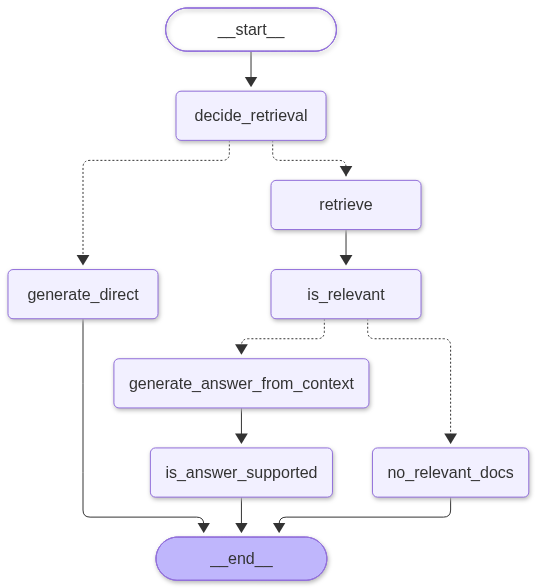

In [30]:
app = graph.compile()

app

In [39]:
result = app.invoke(
    {
        "question": "What is the minimum password length required by the IT security policy?",
        "need_retrieval": False,
        "docs": [],
        "answer": "",
        "is_answer_supported": "",
        "evidence": []
    }
)

In [42]:
print("Question:", result.get("question"))
print("Retrieval required:", result.get("need_retrieval"))
print("Total documents retrieved:", len(result.get("docs", [])))
print("Total relevant documents:", len(result.get("relevant_docs", [])))
print("Answer support status:", result.get("is_answer_supported"))
print("Evidence:", result.get("evidence"))
print("Final answer:", result.get("answer")[0]['text'])

Question: What is the minimum password length required by the IT security policy?
Retrieval required: True
Total documents retrieved: 4
Total relevant documents: 1
Answer support status: fully_supported
Evidence: ['Passwords must have at least 14 characters']
Final answer: The minimum password length required by the IT security policy is 14 characters.


In [43]:
result = app.invoke(
    {
        "question": "Is the company’s leave policy generous for employees?",
        "need_retrieval": False,
        "docs": [],
        "answer": "",
        "is_answer_supported": "",
        "evidence": []
    }
)

In [46]:
print("Question:", result.get("question"))
print("Retrieval required:", result.get("need_retrieval"))
print("Total documents retrieved:", len(result.get("docs", [])))
print("Total relevant documents:", len(result.get("relevant_docs", [])))
print("Answer support status:", result.get("is_answer_supported"))
print("Evidence:", result.get("evidence"))
print("Final answer:\n", result.get("answer")[0]['text'])

Question: Is the company’s leave policy generous for employees?
Retrieval required: True
Total documents retrieved: 4
Total relevant documents: 2
Answer support status: partially_supported
Evidence: ['Annual (earned) leave | 22 working days | Accrues monthly; up to 15 unused days can be carried forward', 'Sick leave | 8 working days', 'Company holidays: 12 fixed holidays per year plus 2 floating holidays chosen by the employee.']
Final answer:
 Based on the provided company documents, employees receive the following leave entitlements per year:

* **Annual (earned) leave:** 22 working days, which accrues monthly. Up to 15 unused days can be carried forward, and up to 10 unused days can be encashed upon exit. (Note: Annual leave of 3 or more days must be applied for at least 10 days in advance.)
* **Sick leave:** 8 working days. (Unused sick leave lapses on March 31 and cannot be carried forward.)
* **Company holidays:** 12 fixed holidays per year, plus 2 floating holidays chosen by the

In [82]:
result = app.invoke(
    {
        "question": "Is this company listed on the stock market? Answer only Yes or No.",
        "need_retrieval": False,
        "docs": [],
        "answer": "",
        "is_answer_supported": "",
        "evidence": []
    }
)

In [83]:
print("Question:", result.get("question"))
print("Retrieval required:", result.get("need_retrieval"))
print("Total documents retrieved:", len(result.get("docs", [])))
print("Total relevant documents:", len(result.get("relevant_docs", [])))
print("Answer support status:", result.get("is_answer_supported"))
print("Evidence:", result.get("evidence"))
print("Final answer:", result.get("answer")[0]['text'])

Question: Is this company listed on the stock market? Answer only Yes or No.
Retrieval required: True
Total documents retrieved: 4
Total relevant documents: 2
Answer support status: not_supported
Evidence: []
Final answer: No


In [60]:
result = app.invoke(
    {
        "question": "How many employees does this company have?",
        "need_retrieval": False,
        "docs": [],
        "answer": "",
        "is_answer_supported": "",
        "evidence": []
    }
)

In [61]:
print("Question:", result.get("question"))
print("Retrieval required:", result.get("need_retrieval"))
print("Total documents retrieved:", len(result.get("docs", [])))
print("Total relevant documents:", len(result.get("relevant_docs", [])))
print("Answer support status:", result.get("is_answer_supported"))
print("Evidence:", result.get("evidence"))
print("Final answer:", result.get("answer"))

Question: How many employees does this company have?
Retrieval required: True
Total documents retrieved: 4
Total relevant documents: 0
Answer support status: 
Evidence: []
Final answer: No answer found.
